In [ ]:
from brian2 import *
import sympy

import plot_utils as pu
start_scope()

seed(11922)  # to get identical figures for repeated runs

################################################################################
# Model parameters
################################################################################
### General parameters
duration = 1.0*second  # Total simulation time
sim_dt = 0.1*ms        # Integrator/sampling step
N_e = 3200             # Number of excitatory neurons
N_i = 800              # Number of inhibitory neurons

### Neuron parameters
E_l = -60*mV           # Leak reversal potential
g_l = 9.99*nS          # Leak conductance
E_e = 0*mV             # Excitatory synaptic reversal potential
E_i = -80*mV           # Inhibitory synaptic reversal potential
C_m = 198*pF           # Membrane capacitance
tau_e = 5*ms           # Excitatory synaptic time constant
tau_i = 10*ms          # Inhibitory synaptic time constant
tau_r = 5*ms           # Refractory period
I_ex = 150*pA          # External current
V_th = -50*mV          # Firing threshold
V_r = E_l              # Reset potential

### Synapse parameters
w_e = 0.05*nS          # Excitatory synaptic conductance
w_i = 1.0*nS           # Inhibitory synaptic conductance
U_0 = 0.6              # Synaptic release probability at rest
Omega_d = 2.0/second   # Synaptic depression rate
Omega_f = 3.33/second  # Synaptic facilitation rate

################################################################################
# Model definition
################################################################################
# Set the integration time (in this case not strictly necessary, since we are
# using the default value)
defaultclock.dt = sim_dt

### Neurons
neuron_eqs = '''
dv/dt = (g_l*(E_l-v) + g_e*(E_e-v) + g_i*(E_i-v) +
         I_ex)/C_m    : volt (unless refractory)
dg_e/dt = -g_e/tau_e  : siemens  # post-synaptic exc. conductance
dg_i/dt = -g_i/tau_i  : siemens  # post-synaptic inh. conductance
'''
neurons = NeuronGroup(N_e + N_i, model=neuron_eqs,
                      threshold='v>V_th', reset='v=V_r',
                      refractory='tau_r', method='euler')
# Random initial membrane potential values and conductances
neurons.v = 'E_l + rand()*(V_th-E_l)'
neurons.g_e = 'rand()*w_e'
neurons.g_i = 'rand()*w_i'
exc_neurons = neurons[:N_e]
inh_neurons = neurons[N_e:]

### Synapses
synapses_eqs = '''
# Usage of releasable neurotransmitter per single action potential:
du_S/dt = -Omega_f * u_S     : 1 (event-driven)
# Fraction of synaptic neurotransmitter resources available:
dx_S/dt = Omega_d *(1 - x_S) : 1 (event-driven)
'''
synapses_action = '''
u_S += U_0 * (1 - u_S)
r_S = u_S * x_S
x_S -= r_S
'''
exc_syn = Synapses(exc_neurons, neurons, model=synapses_eqs,
                   on_pre=synapses_action+'g_e_post += w_e*r_S')
inh_syn = Synapses(inh_neurons, neurons, model=synapses_eqs,
                   on_pre=synapses_action+'g_i_post += w_i*r_S')

exc_syn.connect(p=0.05)
inh_syn.connect(p=0.2)
# Start from "resting" condition: all synapses have fully-replenished
# neurotransmitter resources
exc_syn.x_S = 1
inh_syn.x_S = 1

# ##############################################################################
# # Monitors
# ##############################################################################
# Note that we could use a single monitor for all neurons instead, but in this
# way plotting is a bit easier in the end
exc_mon = SpikeMonitor(exc_neurons)
inh_mon = SpikeMonitor(inh_neurons)

### We record some additional data from a single excitatory neuron
ni = 50
# Record conductances and membrane potential of neuron ni
state_mon = StateMonitor(exc_neurons, ['v', 'g_e', 'g_i'], record=ni)
# We make sure to monitor synaptic variables after synapse are updated in order
# to use simple recurrence relations to reconstruct them. Record all synapses
# originating from neuron ni
synapse_mon = StateMonitor(exc_syn, ['u_S', 'x_S'],
                           record=exc_syn[ni, :], when='after_synapses')

# ##############################################################################
# # Simulation run
# ##############################################################################
run(duration, report='text')





Starting simulation at t=0. s for a duration of 1. s
1. s (100%) simulated in < 1s


WARNING    <>:68: SyntaxWarning: invalid escape sequence '\,'
 [py.warnings]
WARNING    <>:68: SyntaxWarning: invalid escape sequence '\,'
 [py.warnings]
WARNING    /tmp/ipykernel_26957/2843796325.py:68: SyntaxWarning: invalid escape sequence '\,'
  ylabel='synaptic\nvariables\n$u_S,\,x_S$')
 [py.warnings]


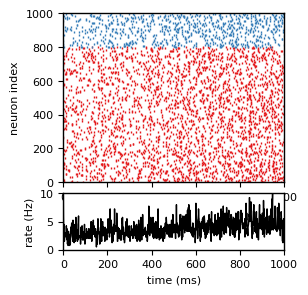

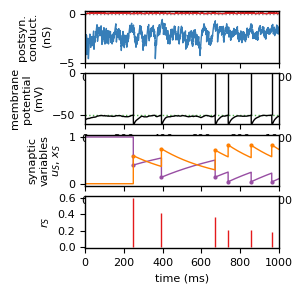

In [11]:
################################################################################
# Analysis and plotting
################################################################################
plt.style.use('figures.mplstyle')
### Spiking activity (w/ rate)
fig1, ax = plt.subplots(nrows=2, ncols=1, sharex=False,
                        gridspec_kw={'height_ratios': [3, 1],
                                     'left': 0.18, 'bottom': 0.18, 'top': 0.95,
                                     'hspace': 0.1},
                        figsize=(3.07, 3.07))
ax[0].plot(exc_mon.t[exc_mon.i <= N_e//4]/ms,
           exc_mon.i[exc_mon.i <= N_e//4], '|', color='C0')
ax[0].plot(inh_mon.t[inh_mon.i <= N_i//4]/ms,
           inh_mon.i[inh_mon.i <= N_i//4]+N_e//4, '|', color='C1')
#pu.adjust_spines(ax[0], ['left'])
ax[0].set(xlim=(0., duration/ms), ylim=(0, (N_e+N_i)//4), ylabel='neuron index')

# Generate frequencies
bin_size = 1*ms
spk_count, bin_edges = np.histogram(np.r_[exc_mon.t/ms, inh_mon.t/ms],
                                    int(duration/ms))
rate = double(spk_count)/(N_e + N_i)/bin_size/Hz
ax[1].plot(bin_edges[:-1], rate, '-', color='k')
ax[1].set(xlim=(0., duration/ms), ylim=(0, 10.),
          xlabel='time (ms)', ylabel='rate (Hz)')

### Dynamics of a single neuron
fig2, ax = plt.subplots(4, sharex=False,
                       gridspec_kw={'left': 0.27, 'bottom': 0.18, 'top': 0.95,
                                    'hspace': 0.2},
                       figsize=(3.07, 3.07))
### Postsynaptic conductances
ax[0].plot(state_mon.t/ms, state_mon.g_e[0]/nS, color='C0')
ax[0].plot(state_mon.t/ms, -state_mon.g_i[0]/nS, color='C1')
ax[0].plot([state_mon.t[0]/ms, state_mon.t[-1]/ms], [0, 0], color='grey',
           linestyle=':')
# Adjust axis
ax[0].set(xlim=(0., duration/ms), ylim=(-5.0, 0.25),
          ylabel=f"postsyn.\nconduct.\n(${sympy.latex(nS)}$)")

### Membrane potential
ax[1].axhline(V_th/mV, color='C2', linestyle=':')  # Threshold
# Artificially insert spikes
ax[1].plot(state_mon.t/ms, state_mon.v[0]/mV, color='black')
ax[1].vlines(exc_mon.t[exc_mon.i == ni]/ms, V_th/mV, 0, color='black')
ax[1].set(xlim=(0., duration/ms), ylim=(-1+V_r/mV, 0.),
          ylabel=f"membrane\npotential\n(${sympy.latex(mV)}$)")

### Synaptic variables
# Retrieves indexes of spikes in the synaptic monitor using the fact that we
# are sampling spikes and synaptic variables by the same dt
spk_index = np.in1d(synapse_mon.t, exc_mon.t[exc_mon.i == ni])
ax[2].plot(synapse_mon.t[spk_index]/ms, synapse_mon.x_S[0][spk_index], '.',
           ms=4, color='C3')
ax[2].plot(synapse_mon.t[spk_index]/ms, synapse_mon.u_S[0][spk_index], '.',
           ms=4, color='C4')
# Super-impose reconstructed solutions
time = synapse_mon.t  # time vector
tspk = Quantity(synapse_mon.t, copy=True)  # Spike times
for ts in exc_mon.t[exc_mon.i == ni]:
    tspk[time >= ts] = ts
ax[2].plot(synapse_mon.t/ms, 1 + (synapse_mon.x_S[0]-1)*exp(-(time-tspk)*Omega_d),
           '-', color='C3')
ax[2].plot(synapse_mon.t/ms, synapse_mon.u_S[0]*exp(-(time-tspk)*Omega_f),
           '-', color='C4')
# Adjust axis
ax[2].set(xlim=(0., duration/ms), ylim=(-0.05, 1.05),
          ylabel='synaptic\nvariables\n$u_S,\,x_S$')

nspikes = np.sum(spk_index)
x_S_spike = synapse_mon.x_S[0][spk_index]
u_S_spike = synapse_mon.u_S[0][spk_index]
ax[3].vlines(synapse_mon.t[spk_index]/ms, np.zeros(nspikes),
             x_S_spike*u_S_spike/(1-u_S_spike))
ax[3].set(xlim=(0., duration/ms), ylim=(-0.01, 0.62),
          yticks=np.arange(0, 0.62, 0.2), xlabel='time (ms)', ylabel='$r_S$')



plt.show()

Starting simulation at t=0. s for a duration of 30. s
[1000 ms]  rates (mean): 4.3 Hz  
Exc weight range: 0.000-1.010 nS
[1500 ms]  rates (mean): 5.6 Hz  
Exc weight range: 0.000-0.677 nS
[2000 ms]  rates (mean): 6.1 Hz  
Exc weight range: 0.000-0.677 nS
[2500 ms]  rates (mean): 4.8 Hz  
Exc weight range: 0.000-1.000 nS
[3000 ms]  rates (mean): 5.2 Hz  
Exc weight range: 0.000-1.000 nS
[3500 ms]  rates (mean): 5.9 Hz  
Exc weight range: 0.000-1.000 nS
[4000 ms]  rates (mean): 5.2 Hz  
Exc weight range: 0.000-1.000 nS
[4500 ms]  rates (mean): 5.6 Hz  
Exc weight range: 0.000-1.000 nS
[5000 ms]  rates (mean): 5.7 Hz  
Exc weight range: 0.000-1.000 nS
[5500 ms]  rates (mean): 2.5 Hz  
Exc weight range: 0.000-2.000 nS
[6000 ms]  rates (mean): 0.0 Hz  
Exc weight range: 0.010-3.000 nS
[6500 ms]  rates (mean): 0.0 Hz  
Exc weight range: 0.010-4.000 nS
[7000 ms]  rates (mean): 0.0 Hz  
Exc weight range: 0.010-5.000 nS
[7500 ms]  rates (mean): 0.0 Hz  
Exc weight range: 0.010-6.000 nS
[8000 ms

WARNING    /tmp/ipykernel_80676/2753408975.py:174: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
 [py.warnings]


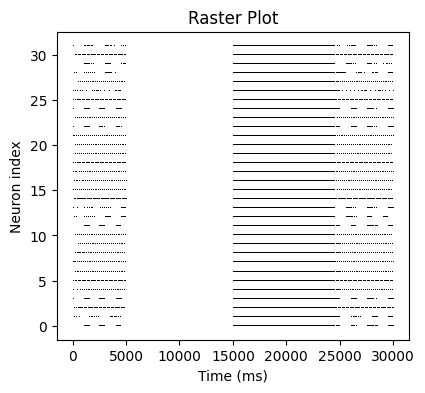

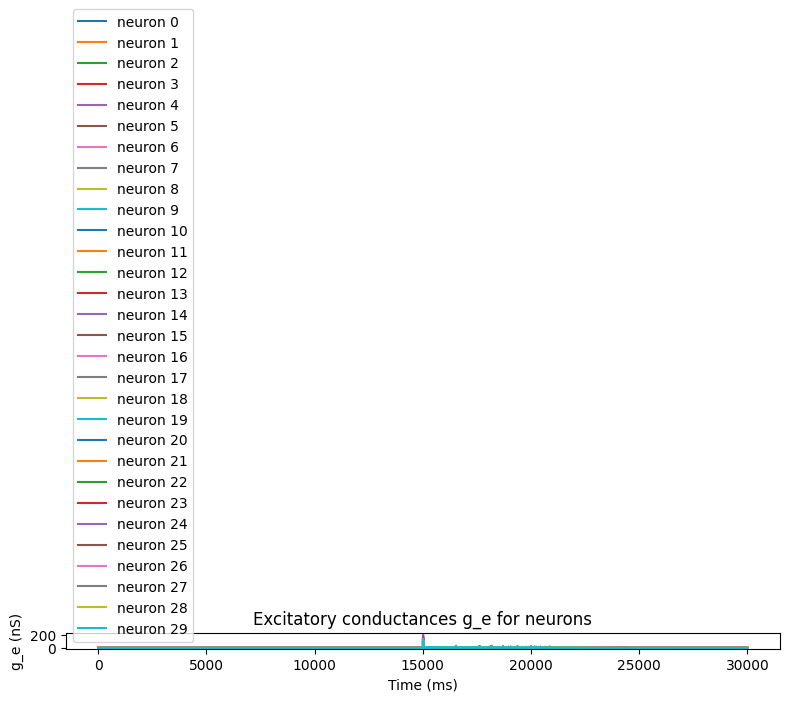

In [1]:
from brian2 import *
import numpy as np
import plot_utils as pu

start_scope()
seed(11922)

################################################################################
# Model parameters
################################################################################
duration   = 30.0*second
sim_dt     = 0.1*ms
N_e        = 32
N_i        = 8
N_total    = N_e + N_i

# alcohol‐withdrawal current window
t_on       = 5000*ms
t_off      = 15000*ms
I_bg       = -1.8*pA  # negative (hyperpolarizing) withdrawal current

# homeostasis
target_rate   = 3*Hz
learning_rate = 1.0*nS  # how strongly to change synaptic strength
plasticity_dt = 0.5*second
window        = 1*second  # compute rate over last 1 s

################################################################################
# Neuron parameters
################################################################################
E_l    = -60*mV
g_l    =  10.0*nS
E_e    =   0*mV
E_i    = -80*mV
C_m    = 198*pF
tau_e  =   5*ms
tau_i  =  10*ms
tau_r  =   5*ms
I_ex   = 101.0*pA
V_th   = -50*mV
V_r    = E_l
################################################################################
# Equations (incl. background current I_bg_dyn)
################################################################################
neuron_eqs = '''
dv/dt = (g_l*(E_l - v) + g_e*(E_e - v) + g_i*(E_i - v)
         + I_ex + I_bg_dyn)/C_m  : volt (unless refractory)
dg_e/dt = -g_e/tau_e            : siemens
dg_i/dt = -g_i/tau_i            : siemens
I_bg_dyn = int(t >= t_on and t < t_off) * I_bg : amp (shared)
'''
#I_inj : amp +I_inj

defaultclock.dt = sim_dt
neurons = NeuronGroup(
    N_total, model=neuron_eqs,
    threshold='v>V_th', reset='v=V_r',
    refractory='tau_r', method='euler'
)
neurons.v   = 'E_l + rand()*(V_th - E_l)'
neurons.g_e = 'rand()*0.05*nS'  # some initial conductance
neurons.g_i = 'rand()*1.0*nS'
# neurons.I_inj = 0*nA

exc_neurons = neurons[:N_e]
inh_neurons = neurons[N_e:]

################################################################################
# Synapses with short-term plasticity
################################################################################
# Tsodyks-Markram style
synapse_eqs = '''
du_S/dt = -Omega_f * u_S : 1 (event-driven)
dx_S/dt =  Omega_d *(1 - x_S) : 1 (event-driven)
w : siemens
'''
on_pre_action = '''
u_S += U_0*(1 - u_S)
r_S = u_S * x_S
x_S -= r_S
g_e_post += w * r_S
'''

# parameters
U_0      = 0.6
Omega_d  = 2.0/second
Omega_f  = 3.33/second
w_e_base = 0.01*nS
w_i_base = 2.0*nS

# P_input = PoissonGroup(N_e, rates=1*Hz)
# #S_input = Synapses(P_input, exc_neurons, on_pre='g_e_post += 0.1*nS')
# S_input = Synapses(P_input, exc_neurons, on_pre='I_inj_post += 0.10*nA')
# S_input.connect(j='i')

exc_syn = Synapses(exc_neurons, neurons,
                   model=synapse_eqs,
                   on_pre=on_pre_action)
inh_syn = Synapses(inh_neurons, neurons,
                   model=synapse_eqs,
                   on_pre=on_pre_action+'g_i_post += w_i_base*r_S')

exc_syn.connect(p=0.40)
inh_syn.connect(p=0.50)
exc_syn.w = w_e_base
exc_syn.x_S = 1
inh_syn.x_S = 1

################################################################################
# Monitors
################################################################################
# spike counts for homeostasis
spike_mon = SpikeMonitor(exc_neurons)
gemon = StateMonitor(neurons, 'g_e', record=range(30))

# some other monitors you already had
exc_mon    = SpikeMonitor(exc_neurons)
inh_mon    = SpikeMonitor(inh_neurons)
state_mon  = StateMonitor(exc_neurons, ['v','g_e','g_i'], record=10)
syn_mon    = StateMonitor(exc_syn, ['u_S','x_S'], record=exc_syn[10, :], when='after_synapses')

################################################################################
# Homeostatic plasticity every plasticity_dt
################################################################################
@network_operation(dt=plasticity_dt)
def homeostatic_plasticity():
    t_now = defaultclock.t
    if t_now < window:
        return
    t0 = t_now - window
    # get arrays of spike times and indices
    times = spike_mon.t
    idxs  = spike_mon.i
    # compute each exc neuron’s rate over last `window`
    rates = np.zeros(N_e)*Hz
    for post in range(N_e):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
    # adjust E→E weights
    for post in range(N_e):
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_e):
            if pre == post:
                continue
            w_old = exc_syn.w[pre, post]
            w_new = clip(w_old + learning_rate * delta, 0*nS, 10000*nS)
            exc_syn.w[pre, post] = w_new
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")
    w_min = np.min(exc_syn.w[:]) / nS
    w_max = np.max(exc_syn.w[:]) / nS
    print(f"Exc weight range: {w_min:.3f}-{w_max:.3f} nS")
################################################################################
# Run & report
################################################################################
run(duration, report='text')

# 1. Raster plot
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spike_mon.t/ms, spike_mon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

plt.figure(figsize=(8, 4))
for idx in range(30):
    plt.plot(gemon.t/ms, gemon.g_e[idx]/nS, label=f'neuron {idx}')
plt.xlabel('Time (ms)')
plt.ylabel('g_e (nS)')
plt.title('Excitatory conductances g_e for neurons')
plt.legend()
plt.tight_layout()
plt.show()


Starting simulation at t=0. s for a duration of 30. s
[1000 ms]  rates (mean): 5.2 Hz  
Exc weight range: 0.000-1.010 nS
[1500 ms]  rates (mean): 6.6 Hz  
Exc weight range: 0.000-1.010 nS
[2000 ms]  rates (mean): 8.2 Hz  
Exc weight range: 0.000-0.210 nS
[2500 ms]  rates (mean): 7.0 Hz  
Exc weight range: 0.000-0.400 nS
[3000 ms]  rates (mean): 5.5 Hz  
Exc weight range: 0.000-1.010 nS
[3500 ms]  rates (mean): 7.2 Hz  
Exc weight range: 0.000-0.800 nS
[4000 ms]  rates (mean): 8.0 Hz  
Exc weight range: 0.000-0.200 nS
[4500 ms]  rates (mean): 6.4 Hz  
Exc weight range: 0.000-1.000 nS
[5000 ms]  rates (mean): 6.2 Hz  
Exc weight range: 0.000-1.000 nS
[5500 ms]  rates (mean): 3.8 Hz  
Exc weight range: 0.000-1.800 nS
[6000 ms]  rates (mean): 0.8 Hz  
Exc weight range: 0.010-2.400 nS
[6500 ms]  rates (mean): 1.4 Hz  
Exc weight range: 0.010-3.000 nS
[7000 ms]  rates (mean): 5.3 Hz  
Exc weight range: 0.010-2.600 nS
[7500 ms]  rates (mean): 6.4 Hz  
Exc weight range: 0.010-2.400 nS
[8000 ms

Text(0, 0.5, 'Neuron index')

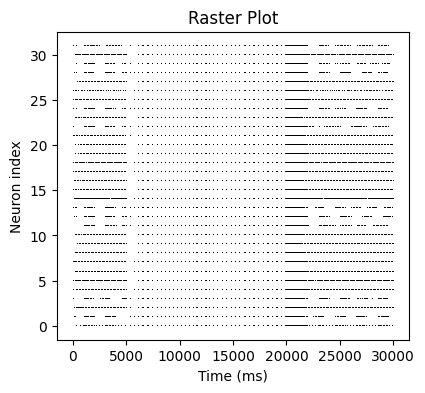

In [1]:
from brian2 import *
import numpy as np
import plot_utils as pu

start_scope()
seed(11922)

################################################################################
# Model parameters
################################################################################
duration   = 30.0*second
sim_dt     = 0.1*ms
N_e        = 32
N_i        = 8
N_total    = N_e + N_i

# alcohol‐withdrawal current window
t_on       = 5000*ms
t_off      = 20000*ms
I_bg       = -1.9999999e-12 * amp  # negative (hyperpolarizing) withdrawal current

# homeostasis
target_rate   = 5*Hz
learning_rate = 1.0*nS  # how strongly to change synaptic strength
plasticity_dt = 0.5*second
window        = 1*second  # compute rate over last 1 s

################################################################################
# Neuron parameters
################################################################################
E_l    = -60*mV
g_l    =  9.8*nS
E_e    =   0*mV
E_i    = -80*mV
C_m    = 200*pF
tau_e  =   5*ms
tau_i  =  10*ms
tau_r  =   5*ms
I_ex   = 100*pA
V_th   = -50*mV
V_r    = E_l
################################################################################
# Equations (incl. background current I_bg_dyn)
################################################################################
neuron_eqs = '''
dv/dt = (g_l*(E_l - v) + g_e*(E_e - v) + g_i*(E_i - v)
         + I_ex + I_bg_dyn)/C_m  : volt (unless refractory)
dg_e/dt = -g_e/tau_e            : siemens
dg_i/dt = -g_i/tau_i            : siemens
I_bg_dyn = int(t >= t_on and t < t_off) * I_bg : amp (shared)
'''
#I_inj : amp +I_inj

defaultclock.dt = sim_dt
neurons = NeuronGroup(
    N_total, model=neuron_eqs,
    threshold='v>V_th', reset='v=V_r',
    refractory='tau_r', method='euler'
)
neurons.v   = 'E_l + rand()*(V_th - E_l)'
neurons.g_e = 'rand()*0.05*nS'  # some initial conductance
neurons.g_i = 'rand()*1.0*nS'
# neurons.I_inj = 0*nA

exc_neurons = neurons[:N_e]
inh_neurons = neurons[N_e:]

################################################################################
# Synapses with short-term plasticity
################################################################################
# Tsodyks-Markram style
synapse_eqs = '''
du_S/dt = -Omega_f * u_S : 1 (event-driven)
dx_S/dt =  Omega_d *(1 - x_S) : 1 (event-driven)
w : siemens
'''
on_pre_action = '''
u_S += U_0*(1 - u_S)
r_S = u_S * x_S
x_S -= r_S
g_e_post += w * r_S
'''

# parameters
U_0      = 0.6
Omega_d  = 2.0/second
Omega_f  = 3.33/second
w_e_base = 0.01*nS
w_i_base = 2.0*nS

# P_input = PoissonGroup(N_e, rates=1*Hz)
# #S_input = Synapses(P_input, exc_neurons, on_pre='g_e_post += 0.1*nS')
# S_input = Synapses(P_input, exc_neurons, on_pre='I_inj_post += 0.10*nA')
# S_input.connect(j='i')

exc_syn = Synapses(exc_neurons, neurons,
                   model=synapse_eqs,
                   on_pre=on_pre_action)
inh_syn = Synapses(inh_neurons, neurons,
                   model=synapse_eqs,
                   on_pre=on_pre_action+'g_i_post += w_i_base*r_S')

exc_syn.connect(p=0.40)
inh_syn.connect(p=0.50)
exc_syn.w = w_e_base
exc_syn.x_S = 1
inh_syn.x_S = 1

################################################################################
# Monitors
################################################################################
# spike counts for homeostasis
spike_mon = SpikeMonitor(exc_neurons)
gemon = StateMonitor(neurons, 'g_e', record=range(30))

# some other monitors you already had
exc_mon    = SpikeMonitor(exc_neurons)
inh_mon    = SpikeMonitor(inh_neurons)
state_mon  = StateMonitor(exc_neurons, ['v','g_e','g_i'], record=10)
syn_mon    = StateMonitor(exc_syn, ['u_S','x_S'], record=exc_syn[10, :], when='after_synapses')

################################################################################
# Homeostatic plasticity every plasticity_dt
################################################################################
@network_operation(dt=plasticity_dt)
def homeostatic_plasticity():
    t_now = defaultclock.t
    if t_now < window:
        return
    t0 = t_now - window
    # get arrays of spike times and indices
    times = spike_mon.t
    idxs  = spike_mon.i
    # compute each exc neuron’s rate over last `window`
    rates = np.zeros(N_e)*Hz
    for post in range(N_e):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
    # adjust E→E weights
    for post in range(N_e):
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_e):
            if pre == post:
                continue
            w_old = exc_syn.w[pre, post]
            w_new = clip(w_old + learning_rate * delta, 0*nS, 10000*nS)
            exc_syn.w[pre, post] = w_new
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")
    w_min = np.min(exc_syn.w[:]) / nS
    w_max = np.max(exc_syn.w[:]) / nS
    print(f"Exc weight range: {w_min:.3f}-{w_max:.3f} nS")
################################################################################
# Run & report
################################################################################
run(duration, report='text')

# 1. Raster plot
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spike_mon.t/ms, spike_mon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')




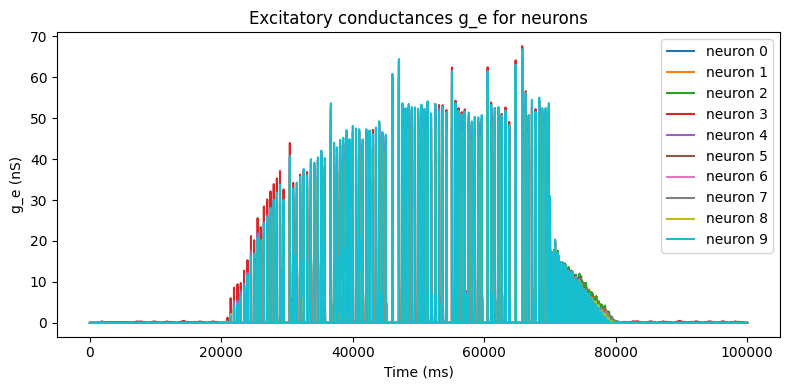

In [19]:
plt.figure(figsize=(8, 4))
for idx in range(10):
    plt.plot(gemon.t/ms, gemon.g_e[idx]/nS, label=f'neuron {idx}')
plt.xlabel('Time (ms)')
plt.ylabel('g_e (nS)')
plt.title('Excitatory conductances g_e for neurons')
plt.legend()
plt.tight_layout()
plt.show()

WARNING    /tmp/ipykernel_80676/2645978686.py:12: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  ax[0].plot(exc_mon.t[exc_mon.i <= N_e//4]/ms,
 [py.warnings]
WARNING    /tmp/ipykernel_80676/2645978686.py:14: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  ax[0].plot(inh_mon.t[inh_mon.i <= N_i//4]/ms,
 [py.warnings]


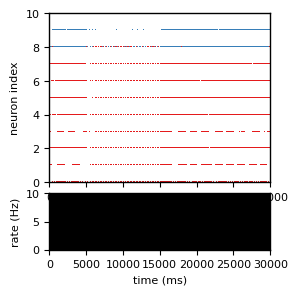

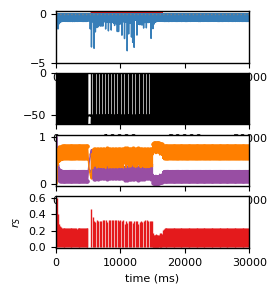

In [28]:
################################################################################
# Analysis and plotting
################################################################################
plt.style.use('figures.mplstyle')
ni=10
### Spiking activity (w/ rate)
fig1, ax = plt.subplots(nrows=2, ncols=1, sharex=False,
                        gridspec_kw={'height_ratios': [3, 1],
                                     'left': 0.18, 'bottom': 0.18, 'top': 0.95,
                                     'hspace': 0.1},
                        figsize=(3.07, 3.07))
ax[0].plot(exc_mon.t[exc_mon.i <= N_e//4]/ms,
           exc_mon.i[exc_mon.i <= N_e//4], ',k', color='C0')
ax[0].plot(inh_mon.t[inh_mon.i <= N_i//4]/ms,
           inh_mon.i[inh_mon.i <= N_i//4]+N_e//4, ',k', color='C1')
#pu.adjust_spines(ax[0], ['left'])
ax[0].set(xlim=(0., duration/ms), ylim=(0, (N_e+N_i)//4), ylabel='neuron index')

# Generate frequencies
bin_size = 1*ms
spk_count, bin_edges = np.histogram(np.r_[exc_mon.t/ms, inh_mon.t/ms],
                                    int(duration/ms))
rate = double(spk_count)/(N_e + N_i)/bin_size/Hz
ax[1].plot(bin_edges[:-1], rate, '-', color='k')
ax[1].set(xlim=(0., duration/ms), ylim=(0, 10.),
          xlabel='time (ms)', ylabel='rate (Hz)')

### Dynamics of a single neuron
fig2, ax = plt.subplots(4, sharex=False,
                       gridspec_kw={'left': 0.27, 'bottom': 0.18, 'top': 0.95,
                                    'hspace': 0.2},
                       figsize=(3.07, 3.07))
### Postsynaptic conductances
ax[0].plot(state_mon.t/ms, state_mon.g_e[0]/nS, color='C0')
ax[0].plot(state_mon.t/ms, -state_mon.g_i[0]/nS, color='C1')
ax[0].plot([state_mon.t[0]/ms, state_mon.t[-1]/ms], [0, 0], color='grey',
           linestyle=':')
# Adjust axis
ax[0].set(xlim=(0., duration/ms), ylim=(-5.0, 0.25))

### Membrane potential
ax[1].axhline(V_th/mV, color='C2', linestyle=':')  # Threshold
# Artificially insert spikes
ax[1].plot(state_mon.t/ms, state_mon.v[0]/mV, color='black')
ax[1].vlines(exc_mon.t[exc_mon.i == ni]/ms, V_th/mV, 0, color='black')
ax[1].set(xlim=(0., duration/ms), ylim=(-1+V_r/mV, 0.))

### Synaptic variables
# Retrieves indexes of spikes in the synaptic monitor using the fact that we
# are sampling spikes and synaptic variables by the same dt
spk_index = np.in1d(syn_mon.t, exc_mon.t[exc_mon.i == ni])
ax[2].plot(syn_mon.t[spk_index]/ms, syn_mon.x_S[0][spk_index], '.',
           ms=4, color='C3')
ax[2].plot(syn_mon.t[spk_index]/ms, syn_mon.u_S[0][spk_index], '.',
           ms=4, color='C4')
# Super-impose reconstructed solutions
time = syn_mon.t  # time vector
tspk = Quantity(syn_mon.t, copy=True)  # Spike times
for ts in exc_mon.t[exc_mon.i == ni]:
    tspk[time >= ts] = ts
ax[2].plot(syn_mon.t/ms, 1 + (syn_mon.x_S[0]-1)*exp(-(time-tspk)*Omega_d),
           '-', color='C3')
ax[2].plot(syn_mon.t/ms, syn_mon.u_S[0]*exp(-(time-tspk)*Omega_f),
           '-', color='C4')
# Adjust axis
ax[2].set(xlim=(0., duration/ms), ylim=(-0.05, 1.05))

nspikes = np.sum(spk_index)
x_S_spike = syn_mon.x_S[0][spk_index]
u_S_spike = syn_mon.u_S[0][spk_index]
ax[3].vlines(syn_mon.t[spk_index]/ms, np.zeros(nspikes),
             x_S_spike*u_S_spike/(1-u_S_spike))
ax[3].set(xlim=(0., duration/ms), ylim=(-0.01, 0.62),
          yticks=np.arange(0, 0.62, 0.2), xlabel='time (ms)', ylabel='$r_S$')



plt.show()

Starting simulation at t=0. s for a duration of 100. s
[1000 ms]  rates (mean): 6.3 Hz  
Exc weight range: 0.000-0.310 nS
[1500 ms]  rates (mean): 6.8 Hz  
Exc weight range: 0.000-0.410 nS
[2000 ms]  rates (mean): 7.1 Hz  
Exc weight range: 0.000-0.310 nS
[2500 ms]  rates (mean): 7.2 Hz  
Exc weight range: 0.000-0.210 nS
[3000 ms]  rates (mean): 7.0 Hz  
Exc weight range: 0.000-0.210 nS
[3500 ms]  rates (mean): 6.9 Hz  
Exc weight range: 0.000-0.410 nS
[4000 ms]  rates (mean): 7.1 Hz  
Exc weight range: 0.000-0.410 nS
[4500 ms]  rates (mean): 7.2 Hz  
Exc weight range: 0.000-0.110 nS
[5000 ms]  rates (mean): 6.9 Hz  
Exc weight range: 0.000-0.200 nS
[5500 ms]  rates (mean): 6.8 Hz  
Exc weight range: 0.000-0.210 nS
[6000 ms]  rates (mean): 7.2 Hz  
Exc weight range: 0.000-0.410 nS
[6500 ms]  rates (mean): 6.9 Hz  
Exc weight range: 0.000-0.410 nS
[7000 ms]  rates (mean): 6.7 Hz  
Exc weight range: 0.000-0.410 nS
[7500 ms]  rates (mean): 7.0 Hz  
Exc weight range: 0.000-0.410 nS
[8000 m

Text(0, 0.5, 'Neuron index')

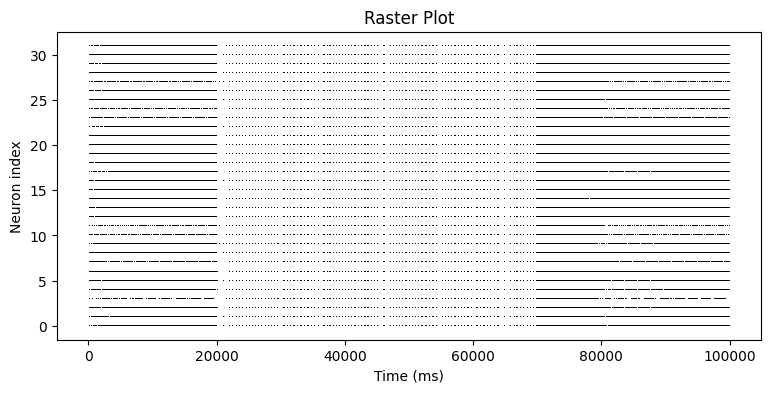

In [15]:
from brian2 import *
import numpy as np
import plot_utils as pu

start_scope()
seed(11922)


# Model parameters
duration   = 100.0*second
sim_dt     = 0.1*ms
N_e        = 32
N_i        = 8
N_total    = N_e + N_i

# alcohol‐withdrawal current window
t_on       = 20000*ms
t_off      = 70000*ms
I_bg       = -2.999999999e-12 * amp  # negative (hyperpolarizing) withdrawal current  -0.999999999e-12

# homeostasis
target_rate   = 5*Hz
learning_rate = 0.5*nS  # how strongly to change synaptic strength
plasticity_dt = 0.5*second
window        = 1*second  
delay = 0*second


# Neuron parameters
E_l    = -60.0*mV
g_l    =  9.8*nS
E_e    =   0*mV
E_i    = -80*mV
C_m    = 200*pF
tau_e  =   5*ms
tau_i  =  10*ms
tau_r  =   5*ms
I_ex   = 199.0*pA #99.0 for vth=50
V_th   = -40*mV
V_r    = E_l

# Equations 
neuron_eqs = '''
dv/dt = (g_l*(E_l - v) + g_e*(E_e - v) + g_i*(E_i - v)
         + I_ex + I_bg_dyn)/C_m  : volt (unless refractory)
dg_e/dt = -g_e/tau_e            : siemens
dg_i/dt = -g_i/tau_i            : siemens
I_bg_dyn = int(t >= t_on and t < t_off) * I_bg : amp (shared)
'''
#I_inj : amp +I_inj

defaultclock.dt = sim_dt
neurons = NeuronGroup(
    N_total, model=neuron_eqs,
    threshold='v>V_th', reset='v=V_r',
    refractory='tau_r', method='euler'
)
neurons.v   = 'E_l' #+ rand()*(V_th - E_l)
neurons.g_e = 0.01*nS  #'rand()*0.05*nS'  
neurons.g_i = 0.01*nS  #'rand()*1.0*nS'
# neurons.I_inj = 0*nA

exc_neurons = neurons[:N_e]
inh_neurons = neurons[N_e:]

# Synapses with short-term plasticity
# Tsodyks-Markram style
synapse_eqs = '''
du_S/dt = -Omega_f * u_S : 1 (event-driven)
dx_S/dt =  Omega_d *(1 - x_S) : 1 (event-driven)
w : siemens
'''
on_pre_action = '''
u_S += U_0*(1 - u_S)
r_S = u_S * x_S
x_S -= r_S
g_e_post += w * r_S
'''

# parameters
U_0      = 0.6
Omega_d  = 2.0/second
Omega_f  = 3.33/second
w_e_base = 0.01*nS
w_i_base = 2.0*nS

# P_input = PoissonGroup(N_e, rates=1*Hz)
# #S_input = Synapses(P_input, exc_neurons, on_pre='g_e_post += 0.1*nS')
# S_input = Synapses(P_input, exc_neurons, on_pre='I_inj_post += 0.10*nA')
# S_input.connect(j='i')

exc_syn = Synapses(exc_neurons, neurons,
                   model=synapse_eqs,
                   on_pre=on_pre_action)
inh_syn = Synapses(inh_neurons, neurons,
                   model=synapse_eqs,
                   on_pre=on_pre_action+'g_i_post += w_i_base*r_S')

exc_syn.connect(p=0.40)
inh_syn.connect(p=0.50)
exc_syn.w = w_e_base
exc_syn.x_S = 1
inh_syn.x_S = 1

# Monitors
spike_mon = SpikeMonitor(exc_neurons)
gemon = StateMonitor(neurons, 'g_e', record=range(30))
exc_mon    = SpikeMonitor(exc_neurons)
inh_mon    = SpikeMonitor(inh_neurons)
state_mon  = StateMonitor(exc_neurons, ['v','g_e','g_i'], record=10)
syn_mon    = StateMonitor(exc_syn, ['u_S','x_S'], record=exc_syn[10, :], when='after_synapses')

# Homeostatic plasticity every plasticity_dt
@network_operation(dt=plasticity_dt)
def homeostatic_plasticity():
    t_now = defaultclock.t-delay
    if t_now < window:
        return
    t0 = t_now - window
    times = spike_mon.t
    idxs  = spike_mon.i
    rates = np.zeros(N_e)*Hz
    for post in range(N_e):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
    for post in range(N_e):
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_e):
            if pre == post:
                continue
            w_old = exc_syn.w[pre, post]
            w_new = clip(w_old + learning_rate * delta, 0*nS, 10000*nS)
            exc_syn.w[pre, post] = w_new
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")
    w_min = np.min(exc_syn.w[:]) / nS
    w_max = np.max(exc_syn.w[:]) / nS
    print(f"Exc weight range: {w_min:.3f}-{w_max:.3f} nS")


run(duration, report='text')

# Raster plot
plt.figure(figsize=(20, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spike_mon.t/ms, spike_mon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')




Text(0, 0.5, 'Neuron index')

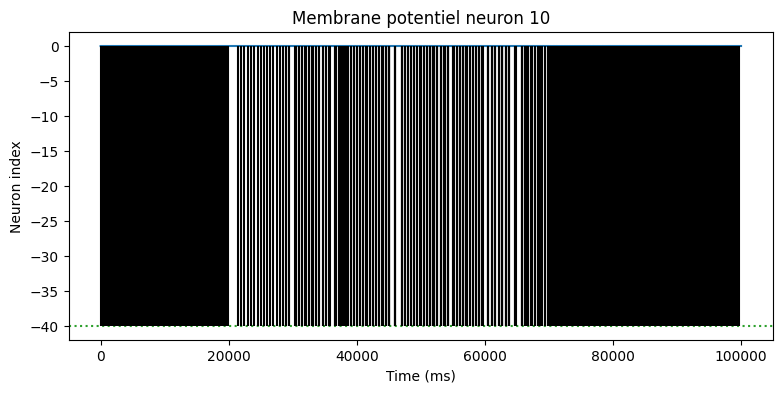

In [17]:

ni=10
plt.figure(figsize=(20, 4))
plt.subplot(121)
plt.title("Membrane potentiel neuron 10")
plt.axhline(V_th/mV, color='C2', linestyle=':')  
plt.plot(state_mon.t/ms, state_mon.v[0])
plt.vlines(exc_mon.t[exc_mon.i == ni]/ms, V_th/mV, 0, color='black')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')


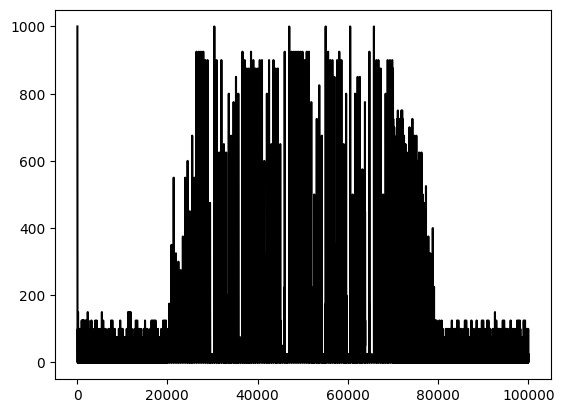

In [18]:
bin_size = 1*ms
spk_count, bin_edges = np.histogram(np.r_[exc_mon.t/ms, inh_mon.t/ms],
                                    int(duration/ms))
rate = double(spk_count)/(N_e + N_i)/bin_size/Hz
plt.plot(bin_edges[:-1], rate, '-', color='k')


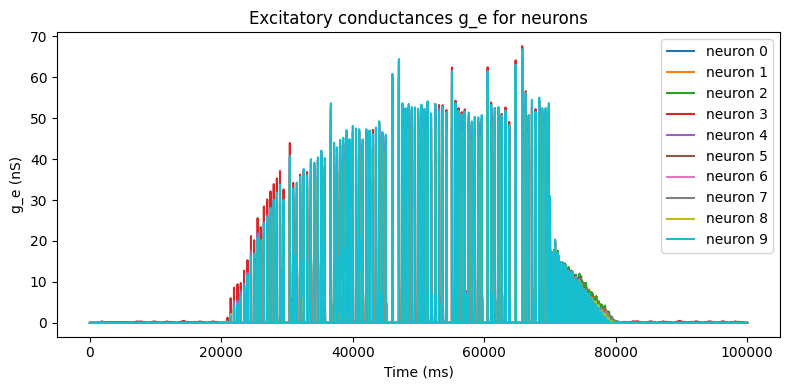

In [20]:
plt.figure(figsize=(8, 4))
for idx in range(10):
    plt.plot(gemon.t/ms, gemon.g_e[idx]/nS, label=f'neuron {idx}')
plt.xlabel('Time (ms)')
plt.ylabel('g_e (nS)')
plt.title('Excitatory conductances g_e for neurons')
plt.legend()
plt.tight_layout()
plt.show()